# 05 · Prediction intervals: are they honest?

**Question:** when the forecast says "80% chance demand falls in this range", does it?

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nhsae import viz
from nhsae.calibrate import standardised_errors
from nhsae.config import LEVELS, RESULTS

viz.set_style()

## 1. Online coverage test
`nhsae.calibrate` compares the model-based Gaussian intervals with three granularities of split-conformal
scaling. Each option is calibrated at every origin using **only errors that had already been observed** by then.

In [2]:
method = json.loads((RESULTS / "interval_method.json").read_text())
for m, d in method.items():
    print(m, "→ chosen:", d["method"])
    for k, v in d["mean_abs_coverage_gap"].items():
        print(f"    {k:34s} mean |coverage − nominal| = {v:.3f}")

attendances → chosen: model-based
    model-based                        mean |coverage − nominal| = 0.109
    conformal: level x horizon band    mean |coverage − nominal| = 0.140
    conformal: per level               mean |coverage − nominal| = 0.152
    conformal: pooled                  mean |coverage − nominal| = 0.153
emergency_admissions → chosen: conformal: pooled
    model-based                        mean |coverage − nominal| = 0.142
    conformal: level x horizon band    mean |coverage − nominal| = 0.112
    conformal: per level               mean |coverage − nominal| = 0.078
    conformal: pooled                  mean |coverage − nominal| = 0.057


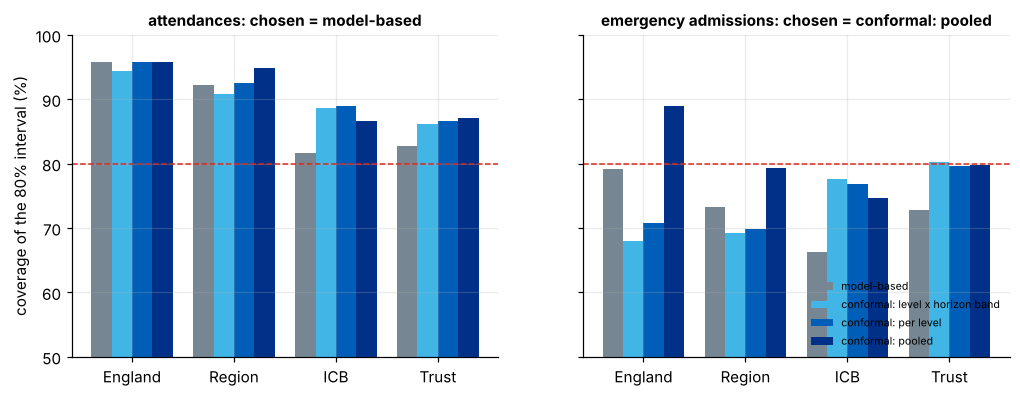

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, measure in zip(axes, ["attendances", "emergency_admissions"]):
    t = pd.read_csv(RESULTS / f"interval_calibration_test_{measure}.csv", header=[0, 1], index_col=0)
    opts = [c for c in t.columns.get_level_values(0).unique()]
    w = 0.8 / len(opts)
    for i, o in enumerate(opts):
        ax.bar(np.arange(4) + (i - (len(opts) - 1) / 2) * w, 100 * t[(o, "in80")].loc[LEVELS], width=w,
               label=o, color=[viz.NHS_GREY, viz.NHS_LIGHT, viz.NHS_BLUE, viz.NHS_DARK][i])
    ax.axhline(80, color=viz.NHS_RED, ls="--", lw=1)
    ax.set_xticks(range(4), LEVELS)
    ax.set_ylim(50, 100)
    ax.set_title(f"{measure.replace('_', ' ')}: chosen = {method[measure]['method']}", fontsize=10)
axes[0].set_ylabel("coverage of the 80% interval (%)")
axes[1].legend(fontsize=7, loc="lower right")
viz.save(fig, "05_coverage")

Finer-grained multipliers adapt more but are noisy where there are few series: England is one series, so its
per-level quantile rests on a handful of errors. For emergency admissions the single pooled multiplier is
the most reliable. For attendances the model-based intervals were already closest to nominal and are kept.

## 2. What calibration can't fix: bias

origin
2023-10-01    0.0275
2024-01-01    0.0072
2024-04-01   -0.0267
2024-07-01   -0.0084
2024-10-01   -0.0137
2025-01-01   -0.0103
2025-04-01   -0.0107
2025-07-01   -0.0245
2025-10-01   -0.0111
dtype: float64

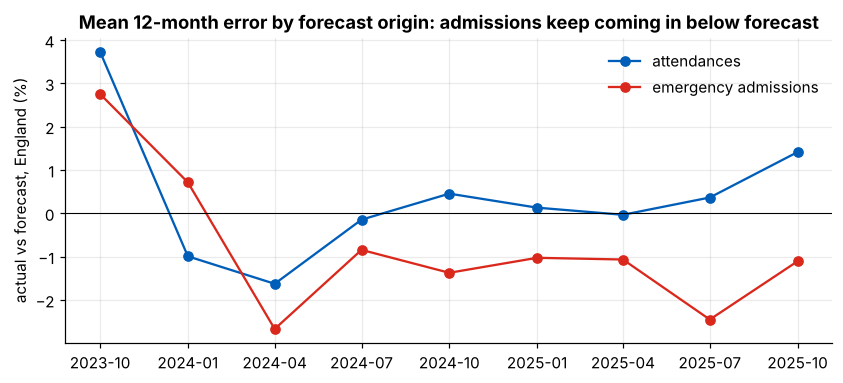

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for measure, c in [("attendances", viz.NHS_BLUE), ("emergency_admissions", viz.NHS_RED)]:
    b = standardised_errors(measure)
    e = b[b.level == "England"]
    pe = e.groupby("origin").apply(lambda g: (g.actual / g.forecast - 1).mean(), include_groups=False)
    ax.plot(pe.index, 100 * pe.values, marker="o", color=c, label=measure.replace("_", " "))
ax.axhline(0, color="black", lw=0.7)
ax.set_ylabel("actual vs forecast, England (%)")
ax.set_title("Mean 12-month error by forecast origin: admissions keep coming in below forecast")
ax.legend()
viz.save(fig, "05_bias")
pe.round(4)

Attendance errors swing either side of zero. Emergency-admission errors have been negative at every origin since
spring 2024: the models keep expecting the 2021–23 recovery in admissions to continue, and it hasn't (notebook 02:
admissions per 100 attendances fell from 30 to about 27). Wider intervals hide this; they don't explain it. In a
real NHS team this goes to the operational leads as a question, before anyone tunes it away.